# Validación cruzada de la Tarea 3: baselines + ridge + ElasticNet + LightGBM
Compara los baselines simples (explorados en `03_exploracion_t3`) con tres familias de modelos mediante validación cruzada temporal, y evalúa el modelo elegido en test. Todo el código está en `logforecast` (`evaluation`, `cv`, `plots`); el notebook solo lo llama.

**Objetivo:** `y = log1p(real) - log1p(pronóstico)` (error relativo en escala log); el modelo predice ese error y la corrección es `expm1(log1p(pron) + delta)`, acotada a >= 0.

**Separación train / test (sin mezclar):**
- **train:** orígenes 22-ene a 13-feb, con CV de origen rodante y ventana expansiva. Todos los ajustes y la elección se hacen aquí.
- **test:** orígenes 14-feb a 28-feb. El modelo elegido se entrena una sola vez con lo conocido al inicio de test y no se reajusta.

**Regla de decisión (solo con train):** un candidato reemplaza al `ratio_mov14` (factor por CD con los últimos 14 días de reales; el mejor baseline en train, ver `03_exploracion_t3`) si su WAPE de CV es menor y gana en al menos 3 de 4 bloques de orígenes. Para ElasticNet y LightGBM se mide además contra el mejor ridge.

In [1]:
import pandas as pd

from logforecast import cv, diagnostics, io, plots
from logforecast import evaluation as ev
from logforecast import features as F
from logforecast.config import Settings

AVAIL_LAG = 1  # días de rezago con que se conoce el real al emitir

S = Settings.from_env()
frame = diagnostics.build_eval_frame(io.load_orders(S), io.load_forecasts(S))
CDS = sorted(frame[F.CD].unique())

## 1. Baselines (rezago 1)
`base`, `seasonal_naive`, `ratio_cd`, `ratio_cd_h` y `ratio_mov14` (referencia). El detalle con los 4 rezagos está en `03_exploracion_t3`.

In [2]:
BASELINES = {
    "base": ev.SPEC_BASE,
    "seasonal_naive": dict(kind="snaive"),
    "ratio_cd": ev.SPEC_RATIO_CD,
    "ratio_cd_h": dict(kind="ratio", by=[F.CD, F.HOR]),
    "ratio_mov14": ev.SPEC_RATIO_MOV14,
}
_, res_base, tabs_base = ev.run_models(frame, BASELINES, AVAIL_LAG)
(pd.concat(tabs_base, names=["zona", "CD"]) * 100).round(1).unstack("zona")

base       seasonal_naive       ratio_cd       ratio_cd_h        \
zona        train  test          train  test    train  test      train  test   
CD                                                                             
GLOBAL       20.8  20.3           12.0  13.7      9.5   9.1        9.5   9.0   
CD_CENTRO    22.9  21.9           14.4  11.5     12.1  12.5       12.2  12.4   
CD_ESTE      24.7  25.6            8.0  13.3     15.1  16.1       15.6  16.4   
CD_NORTE     10.2   9.1           12.1  18.2      7.7   7.4        7.6   7.1   
CD_OESTE     22.1  23.5           14.9  12.0      7.8   8.4        7.8   8.1   
CD_PACIFICO  21.7  24.5            9.2  10.3      8.4   8.3        8.4   8.6   
CD_SUR       31.3  31.4           11.7  10.3      8.8   6.8        8.8   6.7   

            ratio_mov14        
zona              train  test  
CD                             
GLOBAL              9.5   9.2  
CD_CENTRO          12.1  12.7  
CD_ESTE            14.7  16.2  
CD_NORTE            7.7   7.6  
CD_OESTE            8.1   9.2  
CD_PACIFICO         8.5   8.0  
CD_SUR              8.8   6.7

**CD_ESTE:** el `seasonal_naive` le gana con claridad a los ratios, en train (8,0% vs ~15%) y en test (13,3% vs ~16%). Su sesgo es estable en el tiempo (+25%, ver `03_exploracion_t3`), pero tiene una dinámica semanal que un factor fijo no captura; por eso es el CD con más error residual tras la corrección, también con los modelos de las secciones siguientes.

## 2. Validación cruzada de las tres familias (train)
Ridge (`alpha`), ElasticNet (`alpha` x `l1_ratio`) y LightGBM (`num_leaves` x `n_estimators` x `min_child_samples`), todos sobre las mismas features (`F.CORE + F.EXTRA` + dummies de CD) y las mismas filas de CV.

In [3]:
feat = F.build_features(frame, avail_lag=AVAIL_LAG)
study = cv.run_cv_study(feat, {**cv.ridge_specs(), **cv.enet_specs(), **cv.lgbm_specs()}, AVAIL_LAG)
print(study.info())
display(study.best_table())
study.table()

CV (train): 23 origenes | entrena con 444 filas (primero) a 972 (ultimo) | filas de CV: 516
Test: 15 origenes | modelo unico entrenado con 996 filas
base: 20.76% | ratio_mov14: 9.46%


,mejor config,WAPE CV (%)
ridge,alpha=100,7.78
enet,l1_ratio=0.1 alpha=0.1,7.73
lgbm,leaves=8 n=100 min_child=20,7.84


,modelo,config,WAPE CV (%)
0,enet,l1_ratio=0.1 alpha=0.1,7.73
1,enet,l1_ratio=0.5 alpha=0.01,7.76
2,enet,l1_ratio=0.9 alpha=0.01,7.76
3,enet,l1_ratio=1 alpha=0.01,7.77
4,ridge,alpha=100,7.78
5,enet,l1_ratio=0.1 alpha=0.01,7.81
6,enet,l1_ratio=1 alpha=0.001,7.82
7,enet,l1_ratio=0.9 alpha=0.001,7.82
8,ridge,alpha=10,7.84
9,lgbm,leaves=8 n=100 min_child=20,7.84


## 3. Dispersión entre bloques de orígenes (train)

In [4]:
study.block_table().round(2)

,22-Jan..27-Jan,28-Jan..02-Feb,03-Feb..08-Feb,09-Feb..13-Feb,media,desv
ratio_mov14,10.30,9.13,10.21,7.39,9.26,1.36
base,20.58,20.24,21.63,20.47,20.73,0.62
ridge (alpha=100),8.29,9.03,7.58,5.14,7.51,1.69
enet (l1_ratio=0.1 alpha=0.1),7.93,8.80,7.86,5.34,7.48,1.49
lgbm (leaves=8 n=100 min_child=20),8.75,8.81,7.58,5.12,7.57,1.73


## 4. Decisión (solo con train)
Cada familia se compara con `ratio_mov14` y con el mejor ridge.

In [5]:
decision = study.decision()
display(decision)
ganador = study.winner()
print("Pasan la regla en train:", study.passing() or "ninguno")
print("DECISIÓN:", f"usar {ganador}" if ganador else f"quedarse con {study.ref_name}")
assert ganador and study.best[ganador] == cv.ELEGIDO, "actualizar cv.ELEGIDO: lo usan el gate (05) y otros notebooks"

,config,WAPE CV (%),ratio_mov14 (%),bloques vs ratio_mov14,reemplaza a ratio_mov14,bloques vs ridge,mejor que ridge
ridge,alpha=100,7.78,9.46,4/4,True,NaN,NaN
enet,l1_ratio=0.1 alpha=0.1,7.73,9.46,4/4,True,2/4,False
lgbm,leaves=8 n=100 min_child=20,7.84,9.46,4/4,True,3/4,False


Pasan la regla en train: ['ridge', 'enet', 'lgbm']
DECISIÓN: usar enet


## 5. Test final (orígenes 14-feb a 28-feb): se mira una sola vez

In [6]:
ho, tab_ho, dif_ho = study.holdout()
print(f"filas de test: {len(ho['base'])}")
display((tab_ho * 100).round(1))
print("Diferencia en puntos de WAPE (negativo = el modelo mejora):")
dif_ho.round(2)

filas de test: 324


,base,ratio_cd,ratio_mov14,ridge_cv,enet_cv,lgbm_cv
GLOBAL,20.3,9.1,9.2,7.3,7.3,7.6
CD_CENTRO,21.9,12.5,12.7,8.2,8.3,7.2
CD_ESTE,25.6,16.1,16.2,10.6,10.7,10.1
CD_NORTE,9.1,7.4,7.6,7.3,7.1,7.8
CD_OESTE,23.5,8.4,9.2,6.7,7.3,6.3
CD_PACIFICO,24.5,8.3,8.0,6.4,7.0,6.0
CD_SUR,31.4,6.8,6.7,6.1,5.5,7.5


Diferencia en puntos de WAPE (negativo = el modelo mejora):


,ridge_cv - ratio_mov14,enet_cv - ratio_mov14,lgbm_cv - ratio_mov14,enet_cv - ridge_cv,lgbm_cv - ridge_cv
GLOBAL,-1.82,-1.91,-1.55,-0.09,0.28
CD_CENTRO,-4.42,-4.32,-5.42,0.09,-1.01
CD_ESTE,-5.60,-5.53,-6.06,0.08,-0.46
CD_NORTE,-0.32,-0.49,0.16,-0.16,0.48
CD_OESTE,-2.52,-1.89,-2.86,0.63,-0.35
CD_PACIFICO,-1.62,-1.07,-2.00,0.56,-0.38
CD_SUR,-0.67,-1.19,0.81,-0.52,1.48


### Gráficos: WAPE de CV por configuración (train) y test final por CD
En los paneles de CV, la línea punteada es la referencia `ratio_mov14`.

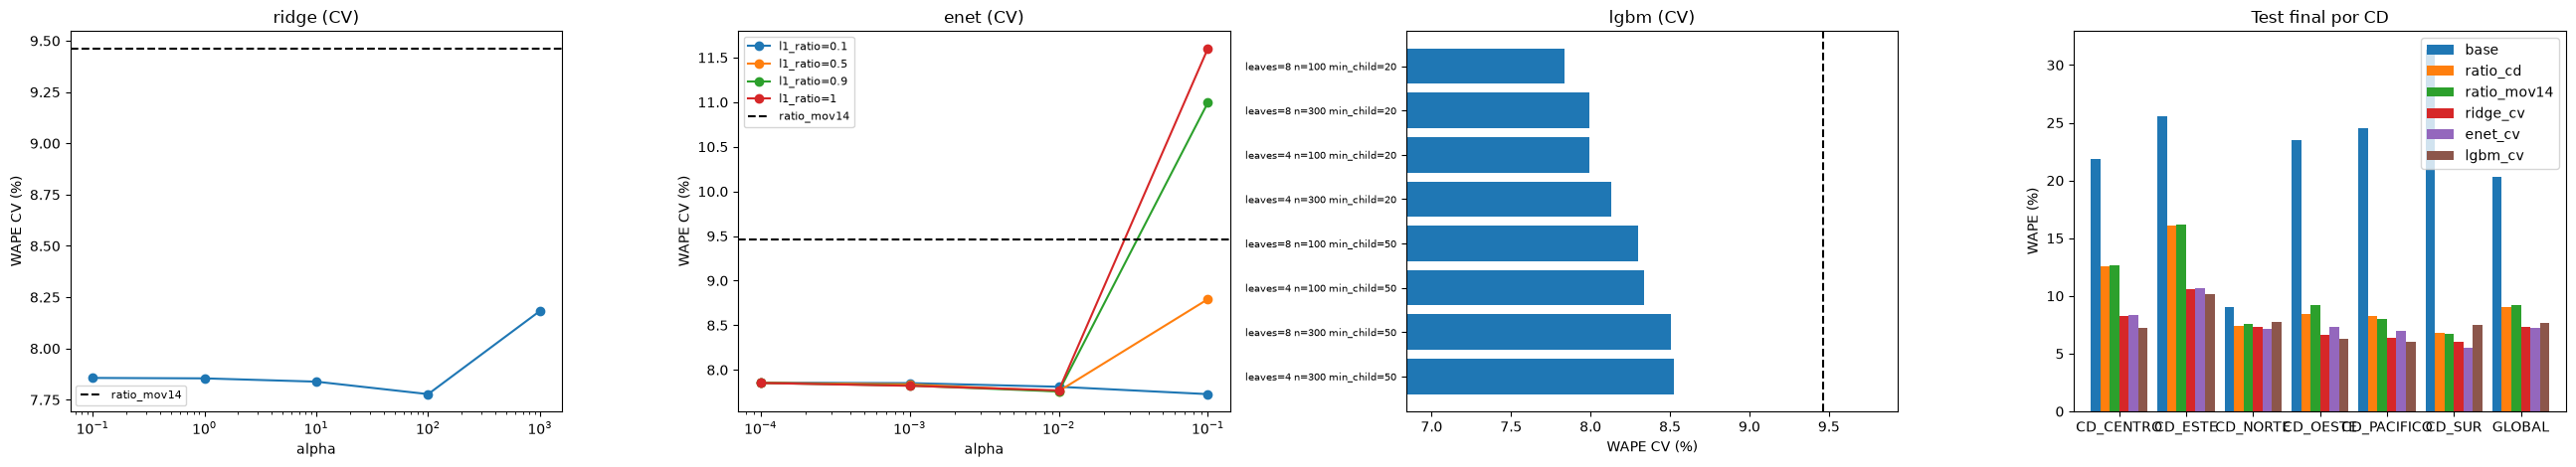

In [7]:
plots.plot_cv_overview(study, tab_ho)

## 6. Qué aprendió cada modelo
Coeficientes estandarizados de ridge y ElasticNet (un 0 en ElasticNet = descartado por la L1; con features correlacionadas la elección es algo arbitraria) e importancia por ganancia de LightGBM (sin signo).

,ridge,enet
err_7,-0.0040,0.0130
err_14,-0.0194,0.0000
h_dias,0.0030,0.0000
dia_semana,-0.0182,-0.0099
finde,-0.0024,-0.0000
pron_vs_rec7,-0.0714,-0.0683
lag7_rel,0.0637,0.0659
pico,0.0013,-0.0000
pico_margen,-0.0132,-0.0077
cd_CD_CENTRO,-0.0477,-0.0310


ElasticNet descarta (coeficiente = 0): ['err_14', 'h_dias', 'finde', 'pico']


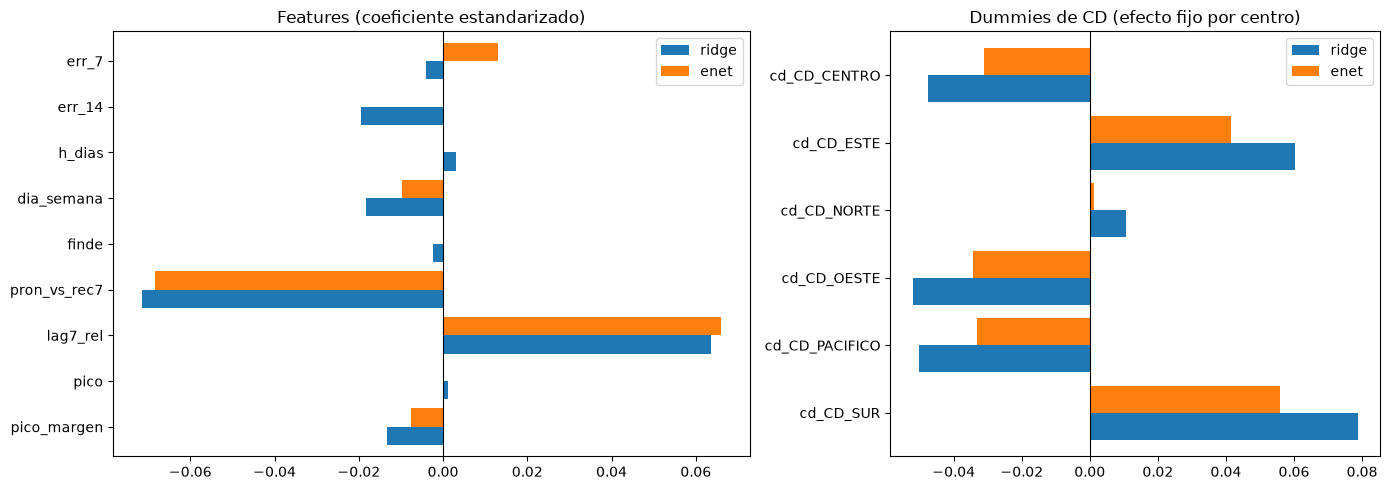

,ganancia (%)
err_7,35.3
pron_vs_rec7,26.0
lag7_rel,15.7
err_14,8.3
cd_CD_SUR,4.3
cd_CD_ESTE,3.1
dia_semana,1.6
pico_margen,1.3
cd_CD_NORTE,1.3
cd_CD_OESTE,1.2


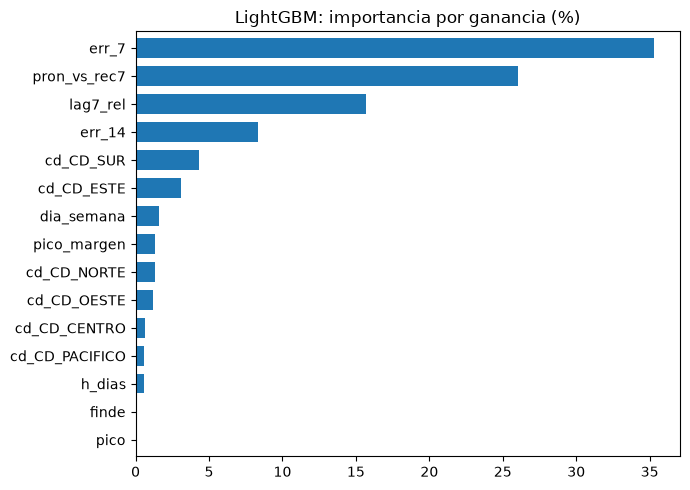

In [8]:
coef = study.coefficients(("ridge", "enet"))
display(coef.round(4))
print("ElasticNet descarta (coeficiente = 0):", list(coef.index[coef["enet"] == 0]))
plots.plot_coefficients(coef, cv.default_cols())
imp = study.importance("lgbm")
display(imp.sort_values(ascending=False).round(1).to_frame("ganancia (%)"))
plots.plot_importance(imp, "LightGBM: importancia por ganancia (%)")

**Lectura de los coeficientes (variables estandarizadas) y de la importancia**
- **Corrección por CD:** las dummies de CD tienen el signo del sesgo de la Tarea 1: positivas en SUR y ESTE (el base subestima) y negativas en CENTRO, OESTE y PACIFICO (sobreestima). NORTE queda cerca de 0.
- **Señal más allá del CD:** `pron_vs_rec7` (≈ −0,07) y `lag7_rel` (≈ +0,065) son las variables con más peso. Si el pronóstico está sobre la demanda reciente o sobre el real de la misma fecha de la semana anterior, el modelo lo corrige a la baja. Sus pesos son casi iguales y de signo opuesto porque son casi redundantes (correlación −0,88 en `03_exploracion_t3`).
- **`err_7` y `err_14` pesan casi 0 en ridge:** el sesgo de cada CD ya lo capturan las dummies. ElasticNet conserva `err_7` y descarta `err_14`; entre variables tan correlacionadas, cuál queda es algo arbitrario.
- **`dia_semana`** (−0,018 en ridge, −0,010 en ElasticNet): la corrección baja a medida que avanza la semana; absorbe el efecto de `finde`, que queda en ~0.
- **`h_dias` y `pico` no aportan** (≈ 0); `pico_margen` aporta poco (≈ −0,01).
- **LightGBM:** `err_7` lidera la ganancia (35%) y las dummies de CD suman solo ~11%. Probablemente el árbol usa `err_7` como sustituto del CD, ya que en los modelos lineales, donde las dummies hacen ese trabajo, pesa ~0. Después vienen `pron_vs_rec7` (26%) y `lag7_rel` (16%), igual que en los lineales. La ganancia no tiene signo.

## 7. Real vs pronóstico base vs modelo elegido (D+1, test)

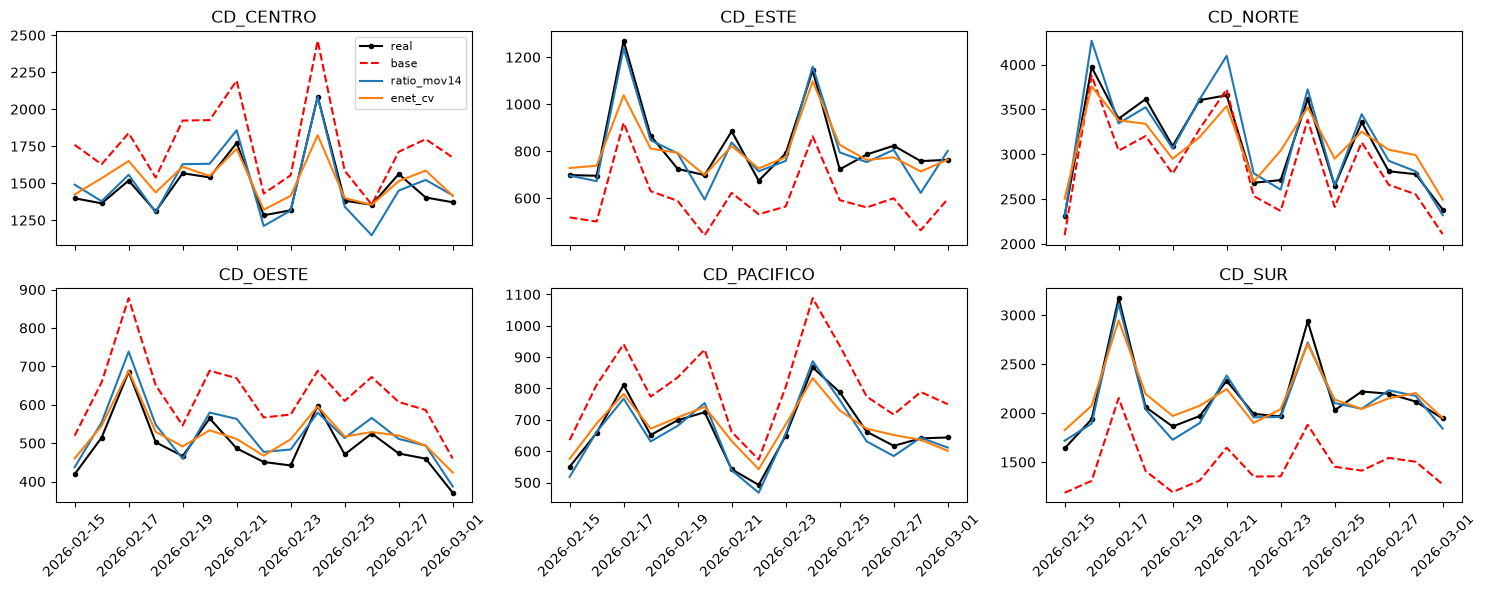

In [9]:
curvas = [study.ref_name] + ([f"{ganador}_cv"] if ganador else [])
plots.plot_real_vs_pred(ho, CDS, curvas=curvas, h_dias=1, zona="test")

## Conclusiones
**Modelo elegido: ElasticNet** (`l1_ratio=0.1`, `alpha=0.1`). Es el de menor WAPE de CV (7,73%) y reemplaza a la referencia `ratio_mov14` en los 4 bloques de orígenes.

**Efecto en test** (orígenes 14-feb a 28-feb, modelo entrenado una vez y congelado):
- El WAPE global baja de 20,3% (base) a 7,3%, 1,9 pp mejor que la referencia `ratio_mov14` (9,2%).
- Mejora contra el base y contra la referencia en los 6 CD: CENTRO 21,9% → 8,3%, ESTE 25,6% → 10,7%, NORTE 9,1% → 7,1%, OESTE 23,5% → 7,3%, PACIFICO 24,5% → 7,0% y SUR 31,4% → 5,5%.
- La mayor parte de la mejora viene de corregir el sesgo por CD: `ratio_mov14` por sí solo baja el WAPE a 9,2% (−11,1 pp). El modelo agrega 1,9 pp usando la relación del pronóstico con la demanda reciente (`pron_vs_rec7`, `lag7_rel`).

**Los tres modelos empatan en la práctica.**
- En CV quedan entre 7,73% y 7,84% (0,11 pp). ElasticNet le gana al ridge en solo 2 de 4 bloques, y ni ElasticNet ni LightGBM cumplen la regla para considerarse mejores que el ridge.
- En test, ElasticNet y ridge quedan en 7,3% y LightGBM en 7,6%. LightGBM es mejor en CENTRO, ESTE, OESTE y PACIFICO, pero en NORTE y SUR queda peor incluso que `ratio_mov14`.
- Se elige ElasticNet porque es lo que indica la regla, definida antes de mirar test; el ridge sería igual de defendible. Las diferencias de décimas entre ambos no son concluyentes.

**Dónde queda error.** CD_ESTE sigue siendo el CD con más error (10,7%): tiene una dinámica semanal que ni los factores por CD ni las features actuales capturan del todo.

**Grillas en el borde.** El mejor ElasticNet usa el `alpha` más alto de la grilla (0,1), y el mejor LightGBM queda en el borde en sus tres hiperparámetros (`num_leaves=8` es el máximo; `n_estimators=100` y `min_child_samples=20`, los mínimos). Ampliar las grillas queda pendiente; como las familias están separadas por centésimas, podría cambiar el orden entre ellas.

## Limitaciones a declarar
- Los primeros orígenes de train entrenan con pocas filas: la CV de enero es ruidosa.
- Orígenes consecutivos comparten casi todo el entrenamiento, así que no son independientes: la dispersión entre bloques es una guía, no un intervalo de confianza.
- Test son 15 orígenes (~324 filas), unas 2 semanas: diferencias de décimas de punto no son concluyentes.
- En test los parámetros no se actualizan: es más exigente que reentrenar a diario.
- Las grillas son chicas (ridge 5 valores de `alpha`, ElasticNet 16 combinaciones, LightGBM 8; 29 en total) y se evalúan sobre los mismos orígenes que la decisión: con más combinaciones crece el riesgo de elegir una por azar.
- ElasticNet: con `alpha` muy chico converge a mínimos cuadrados; con `alpha` grande y `l1_ratio` alto descarta casi todas las variables y empeora (WAPE de CV de 11–12%).
- LightGBM: con pocas filas los árboles tienden a sobreajustar (por eso la grilla es chica y regularizada) y no extrapolan: en picos fuera del rango visto en train la corrección queda acotada.
- `dia_semana` es ordinal: en ridge y ElasticNet impone un efecto lineal de lunes a domingo y no puede representar un pico en martes; LightGBM sí puede, porque corta la variable por tramos.
- Hay solo ~2 meses de historia; no se puede validar estacionalidad anual ni efectos de calendario (feriados).
- Si un modelo complejo no le gana al `ratio_mov14` con holgura, la recomendación honesta es quedarse con el simple.